Problem Statement

E-commerce websites receive thousands of browsing sessions every day, but only a small percentage result in purchases. Predicting purchase intent helps businesses improve recommendations, marketing strategies, and customer engagement. This project develops a machine learning classification system that predicts whether a user session will generate revenue using behavioral session features.


In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve, roc_auc_score, classification_report
from sklearn.compose import make_column_transformer


## Project Workflow

1. Data Loading

2. Data Understanding

3. Data Cleaning

4. Exploratory Data Analysis

5. Feature Engineering

6. Model Building

7. Model Evaluation

8. Summary

In [4]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_shoppers_intention.csv"

shopping = pd.read_csv(DATA_PATH)

shopping.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
shopping.shape

(12330, 18)

In [6]:
shopping.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

## Missing Value Analysis

The dataset contains no missing values, allowing us to proceed directly to exploratory data analysis and preprocessing.

In [7]:
shopping.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [8]:
shopping.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [9]:
shopping.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [10]:
shopping.duplicated().sum()

np.int64(125)

In [11]:
shopping = shopping.drop_duplicates()

## Statistical Summary

This section provides an overview of numerical features including mean, standard deviation, minimum, maximum and quartile values.

## Target Variable Analysis

Revenue represents whether a shopping session ended in a purchase.

False → No Purchase

True → Purchase

In [12]:
shopping.Revenue.value_counts(normalize=True)

Revenue
False    0.843671
True     0.156329
Name: proportion, dtype: float64

In [13]:
shopping.Revenue.value_counts()

Revenue
False    10297
True      1908
Name: count, dtype: int64

In [14]:
shopping.Revenue.value_counts(normalize=True)*100

Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64

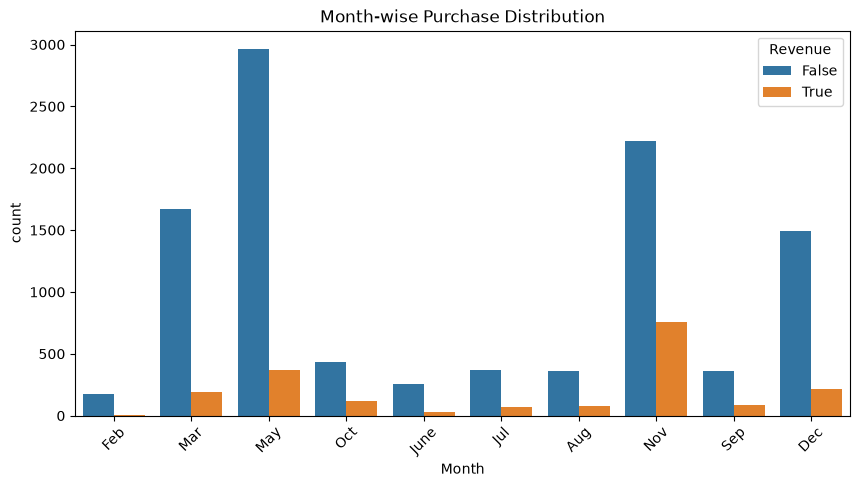

In [15]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=shopping,
    x='Month',
    hue='Revenue'
)

plt.title("Month-wise Purchase Distribution")
plt.xticks(rotation=45)

plt.show()

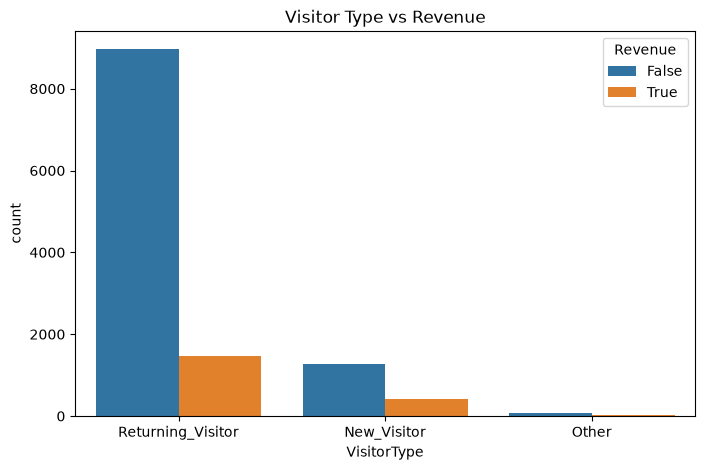

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=shopping,
    x="VisitorType",
    hue="Revenue"
)

plt.title("Visitor Type vs Revenue")

plt.show()

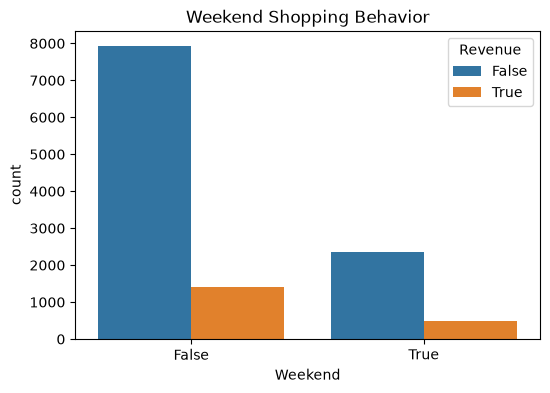

In [17]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=shopping,
    x="Weekend",
    hue="Revenue"
)

plt.title("Weekend Shopping Behavior")

plt.show()

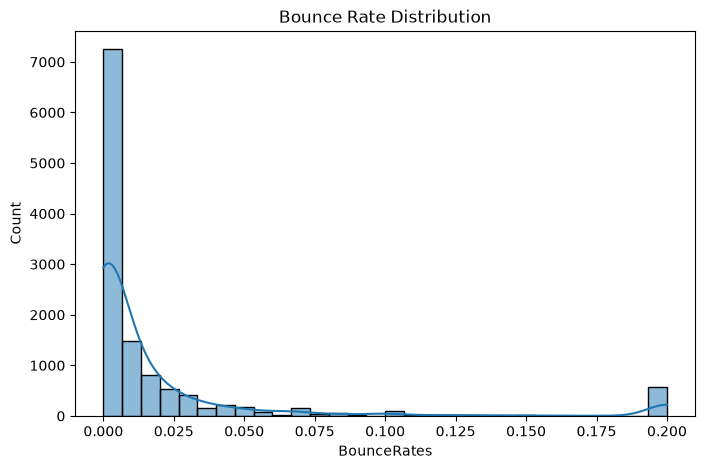

In [18]:
plt.figure(figsize=(8,5))

sns.histplot(
    shopping["BounceRates"],
    bins=30,
    kde=True
)

plt.title("Bounce Rate Distribution")

plt.show()

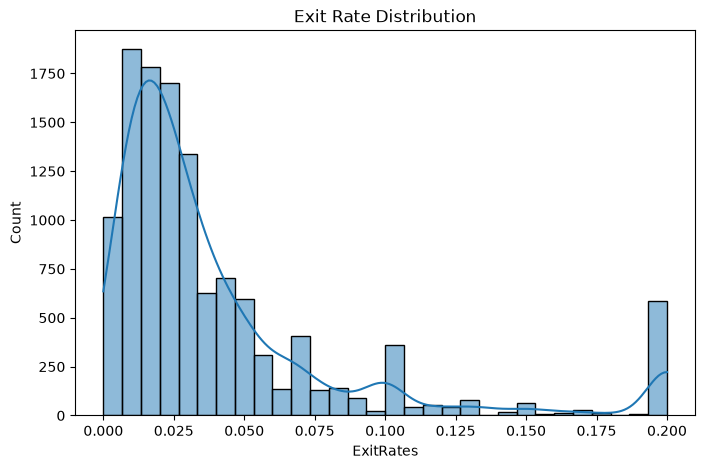

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(
    shopping["ExitRates"],
    bins=30,
    kde=True
)

plt.title("Exit Rate Distribution")

plt.show()

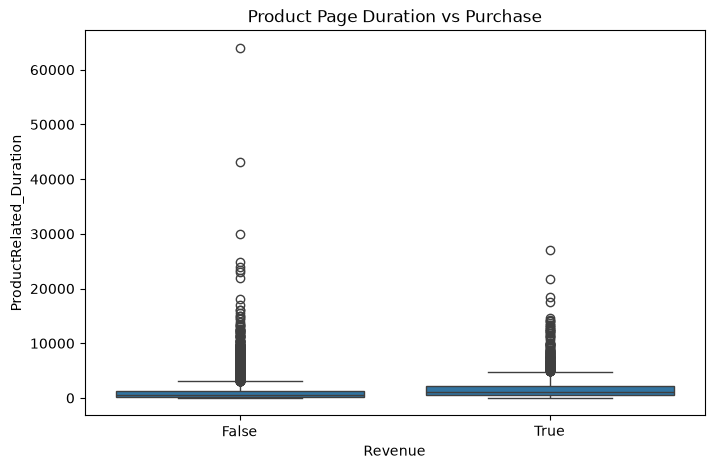

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=shopping,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.title("Product Page Duration vs Purchase")

plt.show()

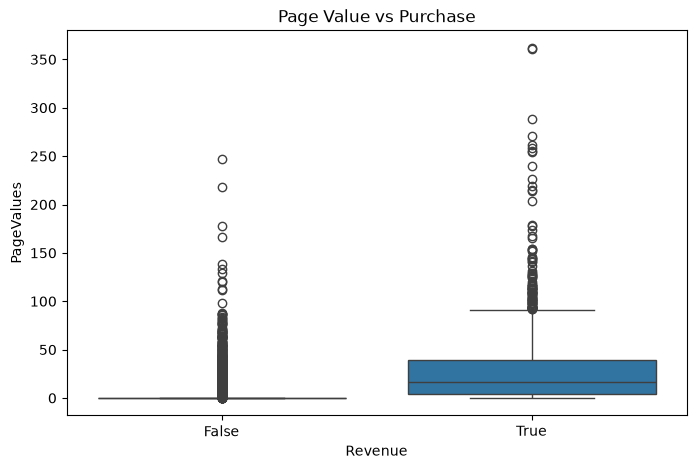

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=shopping,
    x="Revenue",
    y="PageValues"
)

plt.title("Page Value vs Purchase")

plt.show()

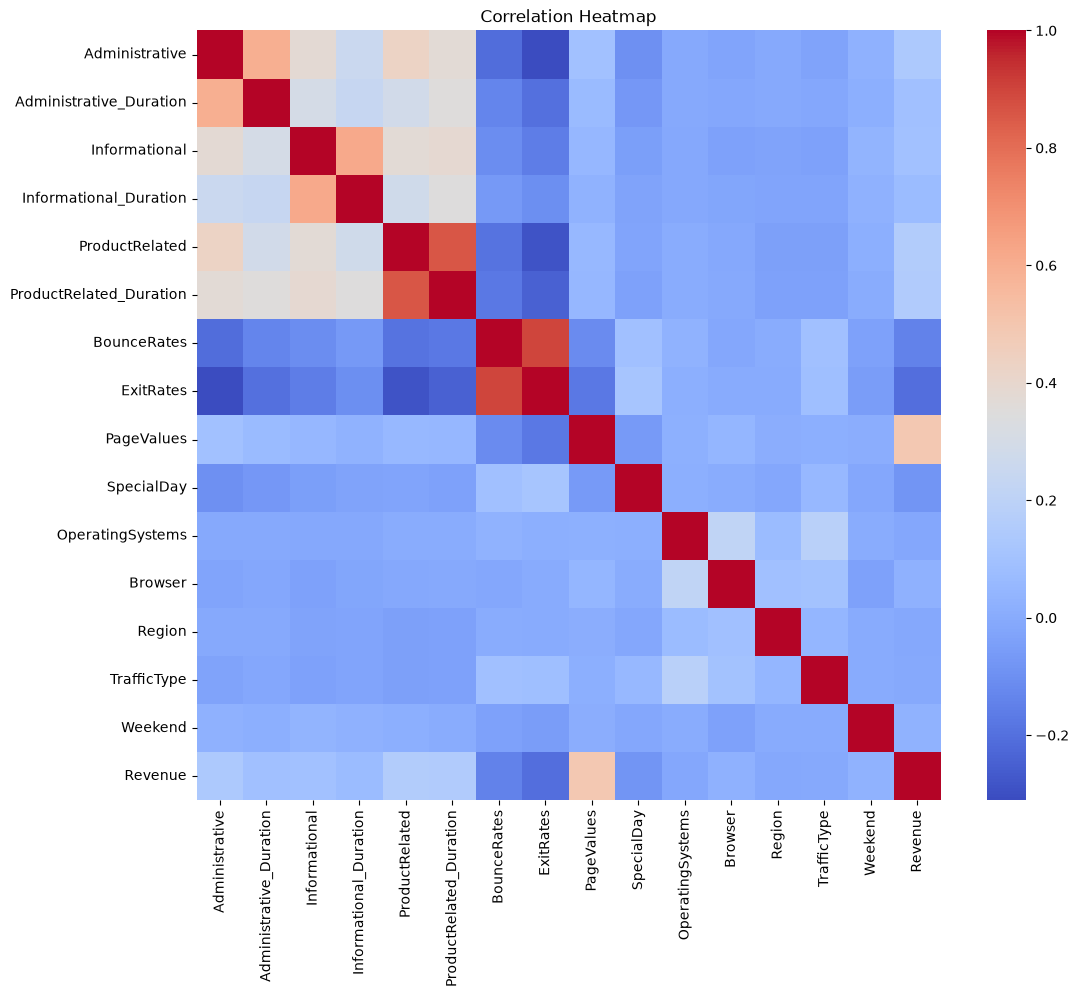

In [22]:
plt.figure(figsize=(12,10))

corr = shopping.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

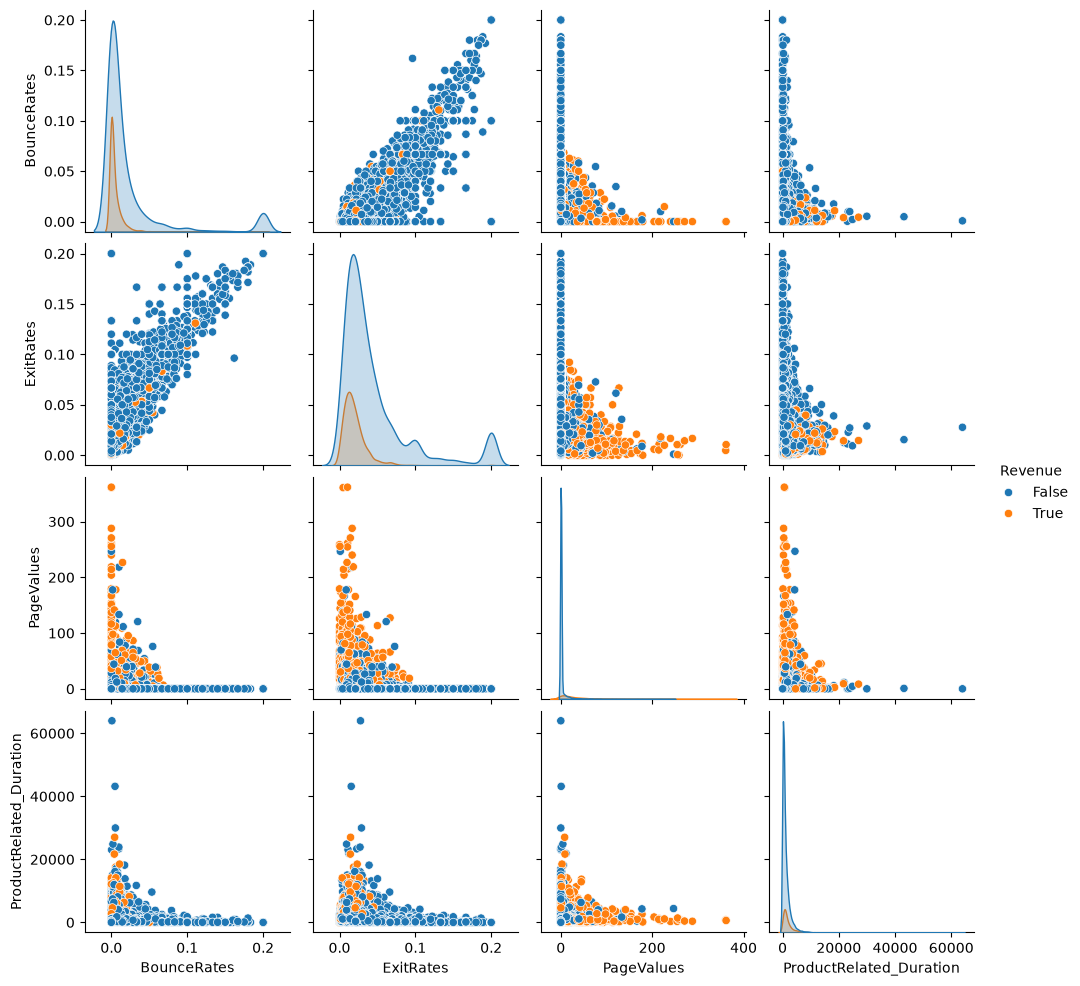

In [23]:
features = [
    "BounceRates",
    "ExitRates",
    "PageValues",
    "ProductRelated_Duration",
    "Revenue"
]

sns.pairplot(
    shopping[features],
    hue="Revenue"
)

plt.show()

In [24]:
X_train, X_test, y_train, y_test = train_test_split(shopping.drop('Revenue' , axis=1), shopping.Revenue, random_state=42, stratify=shopping.Revenue)
print(f'y_train value counts : {y_train.value_counts(normalize=True)}')
print(f'y_test value counts : {y_test.value_counts(normalize=True)}')


y_train value counts : Revenue
False    0.843658
True     0.156342
Name: proportion, dtype: float64
y_test value counts : Revenue
False    0.843709
True     0.156291
Name: proportion, dtype: float64


# Baseline Model

The dataset is imbalanced, with approximately 15% of sessions resulting in a purchase.

A baseline prediction using only the majority class would perform poorly for identifying potential buyers, motivating the use of machine learning models.

In [25]:
categorical_columns = ['Month', 'VisitorType', 'Weekend']

transformer = make_column_transformer((OneHotEncoder(drop='if_binary'), categorical_columns), remainder=StandardScaler())
knn_pipe = Pipeline([('transform', transformer), ('knn', KNeighborsClassifier())])
knn_pipe.fit(X_train, y_train)
#shopping_preds = knn_pipe.predict(X_test)

#print(shopping_preds[:5])
knn_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transform', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

# Model Comparison

To identify the most suitable machine learning algorithm for purchase intent prediction, multiple classification models are trained using the same preprocessing pipeline and evaluated using common performance metrics.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [27]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [28]:
results = []

for name, model in models.items():

    pipe = Pipeline([
        ('transform', transformer),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)

    preds = pipe.predict(X_test)

    probs = pipe.predict_proba(X_test)[:, 1]

    results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_test, preds),

        "Precision": precision_score(y_test, preds),

        "Recall": recall_score(y_test, preds),

        "F1 Score": f1_score(y_test, preds),

        "ROC-AUC": roc_auc_score(y_test, probs)

    })

In [29]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.905636,0.731051,0.626834,0.674944,0.933601
2,Random Forest,0.902359,0.749304,0.563941,0.643541,0.927036
0,Logistic Regression,0.889581,0.773438,0.415094,0.540246,0.896395
1,KNN,0.883683,0.710345,0.431866,0.537158,0.811749


# Model Performance Comparison

The following table compares the performance of multiple machine learning models trained using the same preprocessing pipeline. The evaluation is based on Accuracy, Precision, Recall, F1-Score and ROC-AUC Score.

The best-performing model will be selected for further optimization and threshold tuning.

# Final Selected Model: Gradient Boosting

After comparing Logistic Regression, KNN, Random Forest, and Gradient Boosting, the Gradient Boosting classifier achieved the best overall performance based on Accuracy, Recall, F1-Score, and ROC-AUC. Therefore, it was selected as the final model for purchase intent prediction.

In [30]:
gradient_pipe = Pipeline([
    ('transform', transformer),
    ('gb', GradientBoostingClassifier(random_state=42))
])

gradient_pipe.fit(X_train, y_train)

gradient_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transform', ...), ('gb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

In [43]:
import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
joblib.dump(
    gradient_pipe,
    "../models/gradient_boosting_model.pkl"
)

print("✅ Model saved successfully!")

✅ Model saved successfully!


In [32]:
loaded_model = joblib.load(
    "../models/gradient_boosting_model.pkl"
)

print(type(loaded_model))

<class 'sklearn.pipeline.Pipeline'>


# Feature Importance Analysis

Feature importance helps identify which user browsing behaviors have the greatest influence on purchase intent prediction.

Understanding these features provides valuable business insights and improves model interpretability.

In [33]:
feature_names = gradient_pipe.named_steps['transform'].get_feature_names_out()

importances = gradient_pipe.named_steps['gb'].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(10)

,Feature,Importance
22,remainder__PageValues,0.738458
20,remainder__BounceRates,0.048503
7,onehotencoder__Month_Nov,0.044164
19,remainder__ProductRelated_Duration,0.036362
14,remainder__Administrative,0.027797
21,remainder__ExitRates,0.025991
15,remainder__Administrative_Duration,0.018515
18,remainder__ProductRelated,0.017259
12,onehotencoder__VisitorType_Returning_Visitor,0.009076
6,onehotencoder__Month_May,0.006952


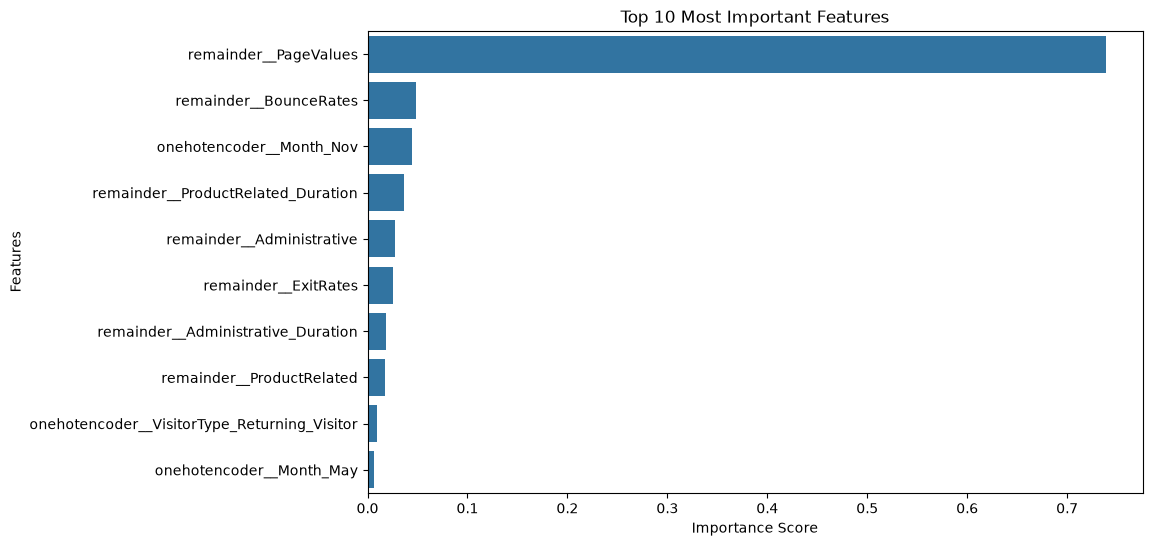

In [34]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Most Important Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

## Business Interpretation

The feature importance analysis indicates that PageValues, ExitRates, BounceRates, and ProductRelated_Duration have the greatest influence on purchase intent prediction.

Users who spend more time on product pages and interact with high-value pages are significantly more likely to complete a purchase. Conversely, higher bounce and exit rates indicate a lower probability of conversion.

These insights can help e-commerce platforms optimize customer experience and improve marketing strategies.

In [35]:
gradient_preds = gradient_pipe.predict(X_test)

gradient_probs = gradient_pipe.predict_proba(X_test)[:, 1]

In [36]:
print("Accuracy :", accuracy_score(y_test, gradient_preds))
print("Precision:", precision_score(y_test, gradient_preds))
print("Recall   :", recall_score(y_test, gradient_preds))
print("F1 Score :", f1_score(y_test, gradient_preds))
print("ROC-AUC  :", roc_auc_score(y_test, gradient_probs))

Accuracy : 0.9056356487549148
Precision: 0.7310513447432763
Recall   : 0.6268343815513627
F1 Score : 0.6749435665914221
ROC-AUC  : 0.9336007815839287


# Final Model Evaluation

The selected Gradient Boosting model is evaluated using multiple classification metrics to ensure reliable purchase intent prediction.

Accuracy alone is insufficient for imbalanced datasets; therefore Precision, Recall, F1-Score and ROC-AUC are also considered.

In [37]:
evaluation_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [

        accuracy_score(y_test, gradient_preds),

        precision_score(y_test, gradient_preds),

        recall_score(y_test, gradient_preds),

        f1_score(y_test, gradient_preds),

        roc_auc_score(y_test, gradient_probs)

    ]

})

evaluation_df

,Metric,Score
0,Accuracy,0.905636
1,Precision,0.731051
2,Recall,0.626834
3,F1 Score,0.674944
4,ROC-AUC,0.933601


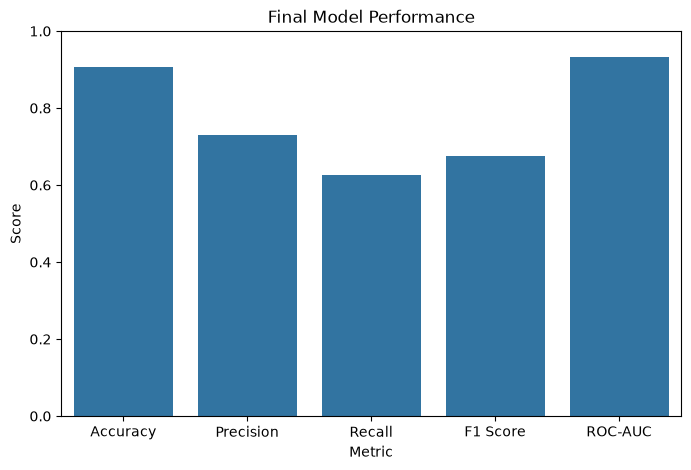

In [38]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=evaluation_df,
    x="Metric",
    y="Score"
)

plt.ylim(0,1)

plt.title("Final Model Performance")

plt.show()

# Key Findings

The exploratory data analysis and machine learning experiments produced the following observations:

- The dataset is imbalanced, with only a small percentage of sessions resulting in purchases.

- Returning visitors demonstrate a higher likelihood of completing purchases than new visitors.

- PageValues and ProductRelated_Duration have a strong positive influence on purchase intent.

- Higher BounceRates and ExitRates are generally associated with lower purchase probability.

- Among all evaluated models, Gradient Boosting achieved the best overall performance with an Accuracy of approximately 90.6% and a ROC-AUC score of 93.36%.

# Conclusion

This project successfully developed a machine learning-based purchase intent prediction system using session-level browsing behavior from an e-commerce platform.

Multiple classification algorithms were evaluated, including Logistic Regression, K-Nearest Neighbors, Random Forest, and Gradient Boosting. Based on comprehensive evaluation metrics, Gradient Boosting was selected as the final model due to its superior Accuracy, Recall, F1-Score, and ROC-AUC performance.

The feature importance analysis further demonstrated that browsing behavior, page values, and product interaction significantly influence purchase decisions.

The developed system can assist e-commerce businesses in identifying high-potential customers and improving marketing and personalization strategies.

# Business Impact

The proposed system provides practical value for online retailers by predicting customer purchase intent before a transaction occurs.

Potential applications include:

- Personalized product recommendations

- Targeted promotional campaigns

- Customer segmentation

- Conversion rate optimization

- Better allocation of marketing resources

These insights can improve customer engagement while increasing business revenue.

# Limitations

Although the model demonstrates strong predictive performance, several limitations exist:

- The dataset represents historical browsing sessions and may not capture evolving user behavior.

- The model is trained on a public dataset and has not been validated on live production traffic.

- External factors such as pricing, advertisements, and competitor influence are not included.

- The project focuses on binary purchase prediction and does not estimate purchase value or customer lifetime value.

# Future Scope

The proposed system can be further enhanced by incorporating:

- Real-time purchase intent prediction

- Deep learning and ensemble methods

- Explainable AI techniques such as SHAP

- Integration with live e-commerce websites

- Personalized recommendation systems

- Customer lifetime value prediction

These improvements would make the system more suitable for deployment in large-scale commercial environments.

# References

1. UCI Machine Learning Repository – Online Shoppers Purchasing Intention Dataset

2. Scikit-learn Documentation

3. Pandas Documentation

4. Matplotlib Documentation

5. Seaborn Documentation

## Evaluation Summary

The Gradient Boosting classifier achieved the highest overall performance among all evaluated models.

It obtained an accuracy of approximately 90.6% and an ROC-AUC score above 93%, demonstrating excellent discrimination between purchasing and non-purchasing sessions.

The model also provides a balanced Precision and Recall, making it suitable for predicting online shopping purchase intent in practical business scenarios.

In [39]:
comparison = results_df.copy()

comparison = comparison.round(4)

comparison = comparison.sort_values(
    by="ROC-AUC",
    ascending=False
)

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.9056,0.7311,0.6268,0.6749,0.9336
2,Random Forest,0.9024,0.7493,0.5639,0.6435,0.9270
0,Logistic Regression,0.8896,0.7734,0.4151,0.5402,0.8964
1,KNN,0.8837,0.7103,0.4319,0.5372,0.8117


## Model Comparison Summary

Gradient Boosting achieved the highest ROC-AUC score (93.36%) and the best overall balance between Precision, Recall, and F1-Score.

Although Random Forest achieved slightly higher Precision, Gradient Boosting provided better Recall and overall classification performance, making it the preferred model for this project.

In [40]:
import sklearn
print(sklearn.__version__)

1.9.0
